#  Boosting Models for Spend Category Prediction

We apply gradient boosting algorithms to predict tourist spending tiers.

Boosting models are powerful for heterogeneous tabular data and
often outperform linear models and SVMs.

Models used:
- XGBoost
- LightGBM
- CatBoost


### Import Libraries

In [3]:
import pandas as pd
import numpy as np

from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
import warnings
import joblib
import os
warnings.filterwarnings("ignore")

### Load Datasets

In [4]:
X_train = pd.read_csv("../data/processed/X_train.csv")
X_val   = pd.read_csv("../data/processed/X_val.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_val   = pd.read_csv("../data/processed/y_val.csv").squeeze()

test = pd.read_csv("../data/processed/test.csv")
test_trip_id = pd.read_csv("../data/processed/test_trip_id.csv").squeeze()

print("Train:", X_train.shape)
print("Val:", X_val.shape)
print("Test:", test.shape)

Train: (10096, 79)
Val: (2524, 79)
Test: (5852, 79)


### Baseline XGBoost

In [9]:
from xgboost import XGBClassifier

X_train_clean = X_train.copy()
X_val_clean   = X_val.copy()
test_clean    = test.copy()

X_train_clean.columns = X_train_clean.columns.str.replace(r"[\[\]<>]", "", regex=True)
X_val_clean.columns   = X_val_clean.columns.str.replace(r"[\[\]<>]", "", regex=True)
test_clean.columns    = test_clean.columns.str.replace(r"[\[\]<>]", "", regex=True)

print("Cleaned feature names.")
print("Example:", list(X_train_clean.columns[:10]))

xgb_base = XGBClassifier(
    objective="multi:softmax",
    num_class=3,
    eval_metric="mlogloss",
    max_depth=8,
    learning_rate=0.1,
    n_estimators=350,
    subsample=0.9,
    colsample_bytree=0.9,
    tree_method="hist",
    random_state=42
)

xgb_base.fit(X_train_clean, y_train)

val_preds_xgb = xgb_base.predict(X_val_clean)

acc_xgb = accuracy_score(y_val, val_preds_xgb)
f1_xgb  = f1_score(y_val, val_preds_xgb, average="macro")

print("\nXGBoost Baseline Performance")
print("----------------------------------")
print(f"Accuracy:  {acc_xgb:.4f}")
print(f"F1 Macro:  {f1_xgb:.4f}\n")

print("Classification Report:")
print(classification_report(y_val, val_preds_xgb))


joblib.dump(xgb_base, "../models/xgb_baseline.joblib")
print("\nSaved model → ../models/xgb_baseline.joblib")


test_preds_xgb = xgb_base.predict(test_clean)

submission_xgb = pd.DataFrame({
    "trip_id": test_trip_id,
    "spend_category": test_preds_xgb
})

submission_xgb.to_csv("../submissions/xgb_baseline.csv", index=False)
print("Submission saved → ../submissions/xgb_baseline.csv")
print("Done.")

Cleaned feature names.
Example: ['num_females', 'num_males', 'is_first_visit', 'mainland_stay_nights', 'island_stay_nights', 'intl_transport_included', 'accomodation_included', 'food_included', 'domestic_transport_included', 'sightseeing_included']

XGBoost Baseline Performance
----------------------------------
Accuracy:  0.7476
F1 Macro:  0.6750

Classification Report:
              precision    recall  f1-score   support

         0.0       0.83      0.85      0.84      1249
         1.0       0.67      0.72      0.70       982
         2.0       0.59      0.42      0.49       293

    accuracy                           0.75      2524
   macro avg       0.70      0.66      0.68      2524
weighted avg       0.74      0.75      0.74      2524


Saved model → ../models/xgb_baseline.joblib
Submission saved → ../submissions/xgb_baseline.csv
Done.


### XGBoost Hyperparameter Tuning

In [13]:
def sanitize_columns(df):
    df = df.copy()
    df.columns = df.columns.str.replace(r"[\[\]<>]", "", regex=True)
    return df

X_train_xgb = sanitize_columns(X_train)
X_val_xgb   = sanitize_columns(X_val)
test_xgb    = sanitize_columns(test)

print("Feature names sanitized for XGB.")


xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
)

param_grid = {
    "max_depth": [4, 6, 8],
    "learning_rate": [0.03, 0.07, 0.1],
    "n_estimators": [250, 400, 600],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0]
}

grid_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=2
)

grid_xgb.fit(X_train_xgb, y_train)

print("\n=====================")
print("Best Hyperparameters")
print("=====================")
print(grid_xgb.best_params_)
print(f"Best CV F1 Macro: {grid_xgb.best_score_:.4f}")


best_xgb = grid_xgb.best_estimator_

val_preds = best_xgb.predict(X_val_xgb)

acc = accuracy_score(y_val, val_preds)
f1  = f1_score(y_val, val_preds, average="macro")

print("\n========== Tuned XGBoost ==========")
print(f"Accuracy:  {acc:.4f}")
print(f"F1 Macro:  {f1:.4f}\n")
print(classification_report(y_val, val_preds))


joblib.dump(best_xgb, "../models/xgb_tuned.joblib")

print("Model saved → ../models/xgb_tuned.joblib")


test_preds = best_xgb.predict(test_xgb)
submission_xgb = pd.DataFrame({
    "trip_id": test_trip_id,
    "spend_category": test_preds
})

os.makedirs("../submissions", exist_ok=True)
submission_xgb.to_csv("../submissions/xgb_tuned.csv", index=False)

print(" Submission generated → ../submissions/xgb_tuned.csv")
print("\n Done.")

Feature names sanitized for XGB.
Fitting 3 folds for each of 162 candidates, totalling 486 fits

Best Hyperparameters
{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 6, 'n_estimators': 400, 'subsample': 0.8}
Best CV F1 Macro: 0.6859

========== Tuned XGBoost ==========
Accuracy:  0.7670
F1 Macro:  0.6853

              precision    recall  f1-score   support

         0.0       0.85      0.86      0.85      1249
         1.0       0.69      0.77      0.73       982
         2.0       0.69      0.37      0.48       293

    accuracy                           0.77      2524
   macro avg       0.74      0.66      0.69      2524
weighted avg       0.77      0.77      0.76      2524

Model saved → ../models/xgb_tuned.joblib
 Submission generated → ../submissions/xgb_tuned.csv

 Done.


### LightGBM

In [6]:
import lightgbm as lgb
warnings.filterwarnings("ignore")

def sanitize_feature_names(df):
    df = df.copy()
    df.columns = (
        df.columns
        .str.replace(r"[^A-Za-z0-9_]", "_", regex=True)  # replace all unsafe chars
        .str.replace(r"__+", "_", regex=True)            # compress "_"
        .str.strip("_")                                  # strip leading/trailing _
    )
    return df

X_train_lgb = sanitize_feature_names(X_train)
X_val_lgb   = sanitize_feature_names(X_val)
test_lgb    = sanitize_feature_names(test)
print("Feature names sanitized.")

lgb_model = lgb.LGBMClassifier(
    objective="multiclass",
    num_class=3,
    boosting_type="gbdt",
    learning_rate=0.05,
    num_leaves=63,
    n_estimators=2000,   # high cap, but ES will stop early
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    n_jobs=-1,
)

callbacks = [
    lgb.early_stopping(50, verbose=True)  # stop if no improvement for 50 rounds
]

lgb_model.fit(
    X_train_lgb,
    y_train,
    eval_set=[(X_val_lgb, y_val)],
    eval_metric="multi_logloss",     # better for multiclass generalization
    callbacks = callbacks
)

print("\nTraining finished.")


val_preds = lgb_model.predict(X_val_lgb)

acc = accuracy_score(y_val, val_preds)
f1  = f1_score(y_val, val_preds, average="macro")

print("\nLightGBM Validation Performance")
print("---------------------------------")
print(f"Accuracy: {acc:.4f}")
print(f"F1 Macro: {f1:.4f}\n")
print(classification_report(y_val, val_preds))


joblib.dump(lgb_model, "../models/lightgbm_es.joblib")
print("Model saved → ../models/lightgbm_es.joblib")


test_preds = lgb_model.predict(test_lgb)
submission_es = pd.DataFrame({
    "trip_id": test_trip_id,
    "spend_category": test_preds
})

submission_es.to_csv("../submissions/lightgbm_es.csv", index=False)

print("Submission created → ../submissions/lightgbm_es.csv")
print("Done.")


Feature names sanitized.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005611 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 383
[LightGBM] [Info] Number of data points in the train set: 10096, number of used features: 77
[LightGBM] [Info] Start training from score -0.703502
[LightGBM] [Info] Start training from score -0.943754
[LightGBM] [Info] Start training from score -2.154281
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[87]	valid_0's multi_logloss: 0.569958

Training finished.

LightGBM Validation Performance
---------------------------------
Accuracy: 0.7627
F1 Macro: 0.6852

              precision    recall  f1-score   support

         0.0       0.84      0.86      0.85      1249
         1.0       0.69      0.75      0.72       982
         2.0       0.65      0.39      0.49       293

    accuracy                           0.76      2

### Lightgbm with optuna

In [11]:
import optuna
from sklearn.model_selection import StratifiedKFold

def sanitize_feature_names(df):
    df = df.copy()
    df.columns = (
        df.columns
        .str.replace(r"[^A-Za-z0-9_]", "_", regex=True)
        .str.replace(r"__+", "_", regex=True)
        .str.strip("_")
    )
    return df

X_opt = sanitize_feature_names(X_train)
y_opt = y_train


def objective(trial):
    params = {
        "objective": "multiclass",
        "num_class": 3,
        "boosting_type": "gbdt",
        "metric": "multi_logloss",

        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15),
        "num_leaves": trial.suggest_int("num_leaves", 31, 255),
        "max_depth": trial.suggest_int("max_depth", 4, 14),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 300),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),

        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 3.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.0, 3.0),

        "n_estimators": 3000,

        # Supress the gain warning
        "min_gain_to_split": 0,
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = []

    for tr, va in cv.split(X_opt, y_opt):
        model = lgb.LGBMClassifier(**params)

        model.fit(
            X_opt.iloc[tr], y_opt.iloc[tr],
            eval_set=[(X_opt.iloc[va], y_opt.iloc[va])],
            eval_metric="multi_logloss",
            callbacks=[
                lgb.early_stopping(50),      # stop if no improvement
                lgb.log_evaluation(0)        # silence logs
            ]
        )

        preds = model.predict(X_opt.iloc[va])
        scores.append(f1_score(y_opt.iloc[va], preds, average="macro"))

    return np.mean(scores)


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=40, show_progress_bar=True)

print("Best F1:", study.best_value)
print("Best Params:", study.best_params)

best_params = study.best_params
best_params.update({
    "objective": "multiclass",
    "num_class": 3,
    "boosting_type": "gbdt",
    "metric": "multi_logloss",
    "n_estimators": 3000
})

final_lgb = lgb.LGBMClassifier(**best_params)

final_lgb.fit(
    X_train_opt, y_train_opt,
    eval_set=[(X_val_lgb, y_val)],
    eval_metric="multi_logloss",
    callbacks=[lgb.early_stopping(80)]
)

print("\nFinal Model Performance")
val_preds = final_lgb.predict(X_val_lgb)
print(classification_report(y_val, val_preds))

joblib.dump(final_lgb, "../models/lightgbm_optuna.joblib")

test_pred = final_lgb.predict(test_lgb)

sub = pd.DataFrame({
    "trip_id": test_trip_id,
    "spend_category": test_pred
})

sub.to_csv("../submissions/lightgbm_optuna.csv", index=False)

print("Submission saved → ../submissions/lightgbm_optuna.csv")
print("Optuna + LightGBM done.")

[I 2025-11-24 14:44:29,654] A new study created in memory with name: no-name-abaf17be-8aff-45ec-9353-8d3be6f7deab


  0%|          | 0/40 [00:00<?, ?it/s]

[LightGBM] [Warning] min_gain_to_split is set=0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0
[LightGBM] [Warning] min_gain_to_split is set=0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000921 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 340
[LightGBM] [Info] Number of data points in the train set: 8076, number of used features: 64
[LightGBM] [Warning] min_gain_to_split is set=0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0
[LightGBM] [Info] Start training from score -0.703603
[LightGBM] [Info] Start training from score -0.943401
[LightGBM] [Info] Start training from score -2.155037
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive

### Catboost

In [13]:
from catboost import CatBoostClassifier, Pool

# --- CatBoost prefers its own Pool format ---
train_pool = Pool(X_train, label=y_train)
val_pool   = Pool(X_val,   label=y_val)

cat_base = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="TotalF1:average=Macro",
    iterations=3000,
    learning_rate=0.05,
    depth=8,
    random_seed=42,
    verbose=False,             # no training spam
)

cat_base.fit(
    train_pool,
    eval_set=val_pool,
    use_best_model=True,
    early_stopping_rounds=50
)

# --------- Evaluation ----------
val_preds = cat_base.predict(X_val)
acc = accuracy_score(y_val, val_preds)
f1  = f1_score(y_val, val_preds, average="macro")

print(" CatBoost Base Model Performance")
print("----------------------------------------")
print(f"Accuracy:  {acc:.4f}")
print(f"F1 Macro:  {f1:.4f}\n")
print("Classification Report:")
print(classification_report(y_val, val_preds))

joblib.dump(cat_base, "../models/catboost_base.joblib")
print("\n CatBoost model saved.")

# Predict on test
test_preds = cat_base.predict(test)

# CatBoost returns shape (n,1), convert to 1D
test_preds = test_preds.ravel()

submission_cat = pd.DataFrame({
    "trip_id": test_trip_id,
    "spend_category": test_preds
})

submission_cat.to_csv("../submissions/catboost_base.csv", index=False)

print("Submission generated → ../submissions/catboost_base.csv")



 CatBoost Base Model Performance
----------------------------------------
Accuracy:  0.7670
F1 Macro:  0.6842

Classification Report:
              precision    recall  f1-score   support

         0.0       0.84      0.87      0.85      1249
         1.0       0.69      0.76      0.72       982
         2.0       0.68      0.37      0.47       293

    accuracy                           0.77      2524
   macro avg       0.74      0.66      0.68      2524
weighted avg       0.76      0.77      0.76      2524


 CatBoost model saved.
Submission generated → ../submissions/catboost_base.csv


### Catboost Tuning

In [7]:
import optuna
from optuna.pruners import MedianPruner
from catboost import CatBoostClassifier, Pool


# ------- Create Pools -------
train_pool = Pool(X_train, y_train)
val_pool = Pool(X_val, y_val)

# ------- Objective Function -------
def objective(trial):

    params = {
        "loss_function": "MultiClass",
        "eval_metric": "Accuracy",
        "iterations": 3000,
        "random_seed": 42,
        "verbose": False,
        "bootstrap_type": trial.suggest_categorical(
            "bootstrap_type",
            ["Bernoulli"]
        ),
        # Hyperparameters to optimize
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.15),
        "depth": trial.suggest_int("depth", 4, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 10.0),
        "border_count": trial.suggest_int("border_count", 32, 255),
    }
    if params["bootstrap_type"] == "Bernoulli":
        params["subsample"] = trial.suggest_float("subsample", 0.6, 1.0)
    model = CatBoostClassifier(**params)

    model.fit(
        train_pool,
        eval_set=val_pool,
        early_stopping_rounds=80,
        use_best_model=True,
        verbose=False,
    )

    preds = model.predict(X_val).ravel()
    return f1_score(y_val, preds, average="macro")


# ----------- Study With Pruner -----------
study = optuna.create_study(
    direction="maximize",
    study_name="catboost_optuna_pruned",
    pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=10),
)

study.optimize(objective, n_trials=40, show_progress_bar=True)

print("\nBest Score:", study.best_value)
print("\nBest Params:")
print(study.best_params)

# ----------- Train Final Model -----------
best_params = study.best_params
best_params.update({
    "loss_function": "MultiClass",
    "eval_metric": "Accuracy",
    "iterations": 3500,
    "random_seed": 42,
    "verbose": False,
})

cat_opt = CatBoostClassifier(**best_params)

cat_opt.fit(
    train_pool,
    eval_set=val_pool,
    use_best_model=True,
    early_stopping_rounds=120,
)

# ----------- Validation Performance -----------
val_preds = cat_opt.predict(X_val).ravel()
val_acc = accuracy_score(y_val, val_preds)
val_f1 = f1_score(y_val, val_preds, average="macro")

print("\n===== CATBOOST OPTUNA + PRUNER =====")
print(f"Accuracy: {val_acc:.4f}")
print(f"F1 Macro: {val_f1:.4f}")

# ----------- Save Model -----------
joblib.dump(cat_opt, "../models/catboost_optuna_pruned.joblib")
print("Saved: ../models/catboost_optuna_pruned.joblib")

# ----------- Submission -----------
test_preds = cat_opt.predict(test).ravel()

submission = pd.DataFrame({
    "trip_id": test_trip_id,
    "spend_category": test_preds.astype(int)
})

submission.to_csv("../submissions/catboost_optuna_pruned.csv", index=False)
print("Submission: ../submissions/catboost_optuna_pruned.csv")


[I 2025-11-24 18:04:23,665] A new study created in memory with name: catboost_optuna_pruned


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2025-11-24 18:04:24,356] Trial 0 finished with value: 0.6767537105798621 and parameters: {'bootstrap_type': 'Bernoulli', 'learning_rate': 0.1448103024995699, 'depth': 5, 'l2_leaf_reg': 4.3397564410871015, 'border_count': 192, 'subsample': 0.7780714415225706}. Best is trial 0 with value: 0.6767537105798621.
[I 2025-11-24 18:04:25,089] Trial 1 finished with value: 0.6678713141282716 and parameters: {'bootstrap_type': 'Bernoulli', 'learning_rate': 0.07143220145863918, 'depth': 6, 'l2_leaf_reg': 3.054280135237736, 'border_count': 59, 'subsample': 0.8497474213768852}. Best is trial 0 with value: 0.6767537105798621.
[I 2025-11-24 18:04:26,433] Trial 2 finished with value: 0.676141187669372 and parameters: {'bootstrap_type': 'Bernoulli', 'learning_rate': 0.034726790836518764, 'depth': 4, 'l2_leaf_reg': 8.042042166247699, 'border_count': 133, 'subsample': 0.833920320691798}. Best is trial 0 with value: 0.6767537105798621.
[I 2025-11-24 18:04:28,331] Trial 3 finished with value: 0.6648781200

### Comparison

,Model,Accuracy,F1 Macro
0,Baseline XGBoost,0.7476,0.6750
1,Tuned XGBoost,0.7670,0.6853
2,LightGBM,0.7627,0.6852
3,LightGBM with Optuna,0.7600,0.6866
4,Catboost,0.7670,0.6842
5,CatBoost (Optuna),0.7643,0.6902


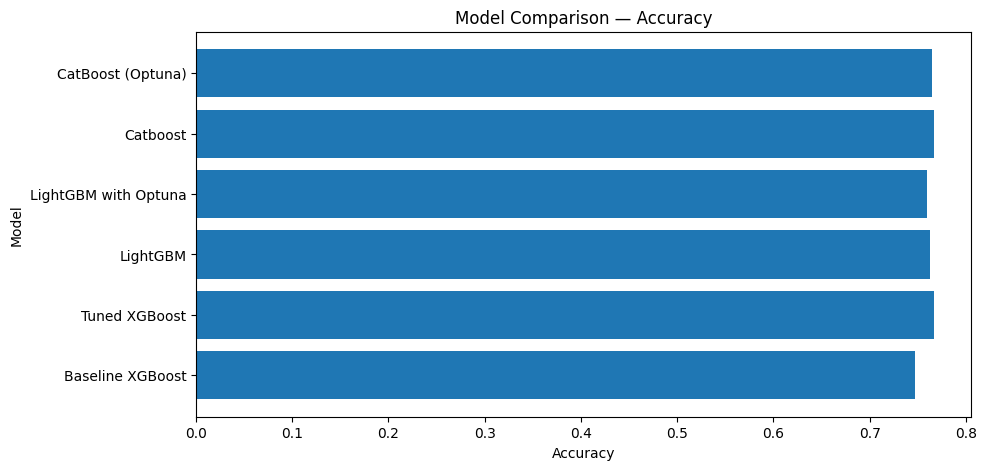

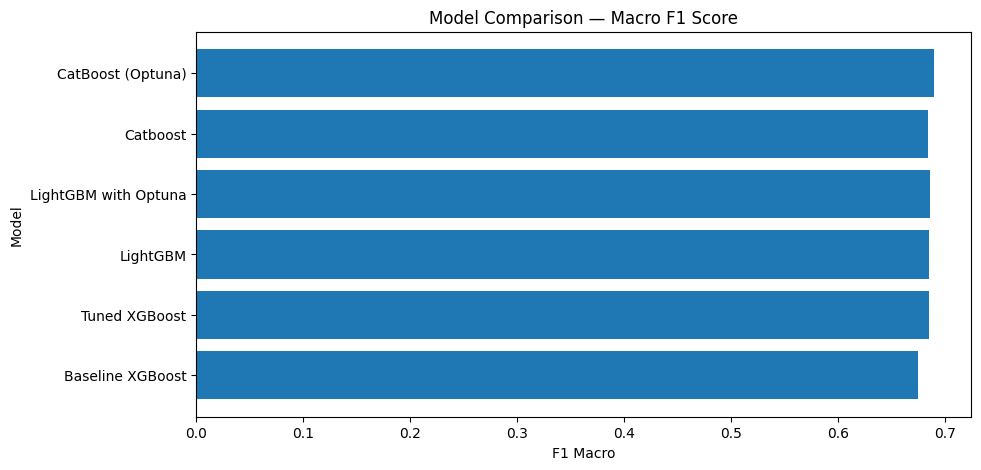

In [11]:
import matplotlib.pyplot as plt


results = {
    "Model": [
        "Baseline XGBoost",
        "Tuned XGBoost",
        "LightGBM",
        "LightGBM with Optuna",
        "Catboost",
        "CatBoost (Optuna)"
    ],
    "Accuracy": [
        0.7476,
        0.7670,
        0.7627,
        0.76,
        0.7670,
        0.7643
    ],
    "F1 Macro": [
        0.6750,
        0.6853,
        0.6852,
        0.6866,
        0.6842,
        0.6902
    ]
}

df_results = pd.DataFrame(results)
display(df_results)

plt.figure(figsize=(10,5))
plt.barh(df_results["Model"], df_results["Accuracy"])
plt.title("Model Comparison — Accuracy")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.show()


plt.figure(figsize=(10,5))
plt.barh(df_results["Model"], df_results["F1 Macro"])
plt.title("Model Comparison — Macro F1 Score")
plt.xlabel("F1 Macro")
plt.ylabel("Model")
plt.show()
